This notebook presents a comprehensive analysis and modeling pipeline built on the Factory Sensor Simulator dataset — a large-scale synthetic dataset designed to simulate machine behavior in a futuristic industrial environment. The process begins with exploratory data analysis (EDA), including dataset structure, missing value inspection, and key distributions. Target variables such as Remaining Useful Life (RUL) and Failure Within 7 Days are examined using histograms, bar plots, and a correlation heatmap. Machine-type-specific failure rates are also visualized to uncover high-risk categories.

A Random Forest Classifier is then implemented to predict whether a machine will fail in the next 7 days, achieving classification metrics like accuracy and confusion matrix results. To improve transparency, SHAP values are calculated and visualized to interpret the feature importance and contribution behind the model’s predictions.

Beyond classification, the notebook also includes a Random Forest Regressor for estimating the continuous target Remaining_Useful_Life_days. Regression performance is evaluated using metrics such as mean squared error and R² score.

Feature engineering is used to introduce binary flags such as High_Vibration and Low_Oil, enabling more interpretable rules and refined models. These engineered features are then analyzed for their relationship with machine failure.

To benchmark performance, the notebook compares the Random Forest model with XGBoost and LightGBM, two powerful gradient boosting frameworks, showcasing their relative classification accuracies.

Lastly, the notebook explores unsupervised learning via PCA (Principal Component Analysis) and KMeans clustering to segment machines into behavioral clusters based on sensor data. This adds an additional layer of insight into how different operational profiles may correlate with failure risks.

<font color = "DeepSkyBlue">**Table of Contents**

1. [Import libraries](#1)
2. [Load data](#2)
3. [Basic overview](#3)
4. [Null values](#4)
5. [Target distribution](#5)
6. [Failure classification distribution](#6)
7. [Correlation heatmap for numeric features](#7)
8. [Failure rate by machine type](#8)
9. [Predictive Model: Random Forest Classifier](#9)
10. [SHAP Explainability](#10)
11. [RUL Regression Model](#11)
12. [Feature Engineering: Binary Threshold Flags](#12)
13. [Model Comparison: XGBoost vs LightGBM](#13)
14. [Failure Clustering (KMeans on PCA)](#14)

<a id = "1"></a><br>
<font color = "DeepSkyBlue">**Import libraries**

This section imports all the essential libraries needed for data analysis, visualization, and machine learning. It includes tools like pandas and numpy for data handling, matplotlib and seaborn for visualizations, and scikit-learn for building and evaluating models. Additionally, it brings in PCA and KMeans for clustering, shap for explainability, and advanced models like XGBoost and LightGBM. The final line suppresses warnings to keep the notebook output clean.

In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import shap
import lightgbm as lgb
import xgboost as xgb
import warnings
warnings.filterwarnings("ignore")

c:\Users\ss57\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<a id = "2"></a><br>
<font color = "DeepSkyBlue">**Load data**

This line loads the synthetic factory sensor dataset into a pandas DataFrame named df from a CSV file located in the Kaggle input directory. It prepares the data for further analysis and modeling throughout the notebook.

In [3]:
# Load data 
df = pd.read_csv("C:/Users/ss57/OneDrive - Caterpillar/Documents 1/Shiva/Uniqueshiva27/Prescriptive Analytics Project/factory_sensor_simulator_2040.csv")


<a id = "3"></a><br>
<font color = "DeepSkyBlue">**Basic overview**

This section provides a quick overview of the dataset by printing its dimensions (shape), data types of each column (dtypes), and the first few rows (head()) to give an initial understanding of the structure and content of the data.

In [4]:
# Basic overview
print("\n--- Dataset Overview ---")
print(df.shape)
print(df.dtypes)
print(df.head())


--- Dataset Overview ---
(500000, 22)
Machine_ID                     object
Machine_Type                   object
Installation_Year               int64
Operational_Hours               int64
Temperature_C                 float64
Vibration_mms                 float64
Sound_dB                      float64
Oil_Level_pct                 float64
Coolant_Level_pct             float64
Power_Consumption_kW          float64
Last_Maintenance_Days_Ago       int64
Maintenance_History_Count       int64
Failure_History_Count           int64
AI_Supervision                   bool
Error_Codes_Last_30_Days        int64
Remaining_Useful_Life_days    float64
Failure_Within_7_Days            bool
Laser_Intensity               float64
Hydraulic_Pressure_bar        float64
Coolant_Flow_L_min            float64
Heat_Index                    float64
AI_Override_Events              int64
dtype: object
  Machine_ID        Machine_Type  Installation_Year  Operational_Hours  \
0  MC_000000               Mixer     

<a id = "4"></a><br>
<font color = "DeepSkyBlue">**Null values**

This section checks for missing values in the dataset by counting null entries in each column and displaying them in descending order. It helps identify which features may require data cleaning or imputation.

In [5]:
# Null values
print("\n--- Null Value Count ---")
print(df.isnull().sum().sort_values(ascending=False))


--- Null Value Count ---
Laser_Intensity               484844
Hydraulic_Pressure_bar        469660
Heat_Index                    454786
Coolant_Flow_L_min            454376
Machine_ID                         0
Machine_Type                       0
Vibration_mms                      0
Temperature_C                      0
Operational_Hours                  0
Installation_Year                  0
Sound_dB                           0
Oil_Level_pct                      0
Coolant_Level_pct                  0
Power_Consumption_kW               0
AI_Supervision                     0
Failure_History_Count              0
Maintenance_History_Count          0
Last_Maintenance_Days_Ago          0
Failure_Within_7_Days              0
Remaining_Useful_Life_days         0
Error_Codes_Last_30_Days           0
AI_Override_Events                 0
dtype: int64


<a id = "5"></a><br>
<font color = "DeepSkyBlue">**Target distribution**

This section visualizes the distribution of the target variable Remaining_Useful_Life_days using a histogram with a kernel density estimate (KDE). It helps reveal how machine lifespans are spread across the dataset, highlighting common lifespan ranges and potential outliers.

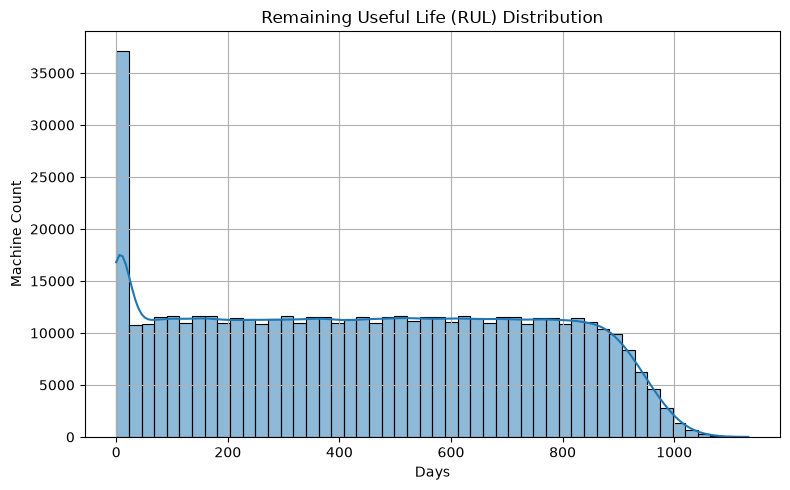

In [6]:
# Target distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Remaining_Useful_Life_days"], bins=50, kde=True)
plt.title("Remaining Useful Life (RUL) Distribution")
plt.xlabel("Days")
plt.ylabel("Machine Count")
plt.grid(True)
plt.tight_layout()
plt.show()

<a id = "6"></a><br>
<font color = "DeepSkyBlue">**Failure classification distribution**

This section creates a count plot to show the distribution of the binary target variable Failure_Within_7_Days. It helps visualize how many machines are expected to fail within the next 7 days versus those that are not, offering insight into class balance for classification tasks.

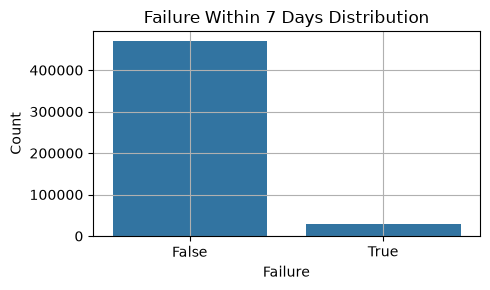

In [7]:
# Failure classification distribution
plt.figure(figsize=(5, 3))
sns.countplot(x="Failure_Within_7_Days", data=df)
plt.title("Failure Within 7 Days Distribution")
plt.xlabel("Failure")
plt.ylabel("Count")
plt.grid(True)
plt.tight_layout()
plt.show()

<a id = "7"></a><br>
<font color = "DeepSkyBlue">**Correlation heatmap for numeric features**

This section generates a correlation heatmap for all numerical features (excluding the target Failure_Within_7_Days). It visually highlights the strength and direction of relationships between features, helping identify multicollinearity or potential predictors for modeling.

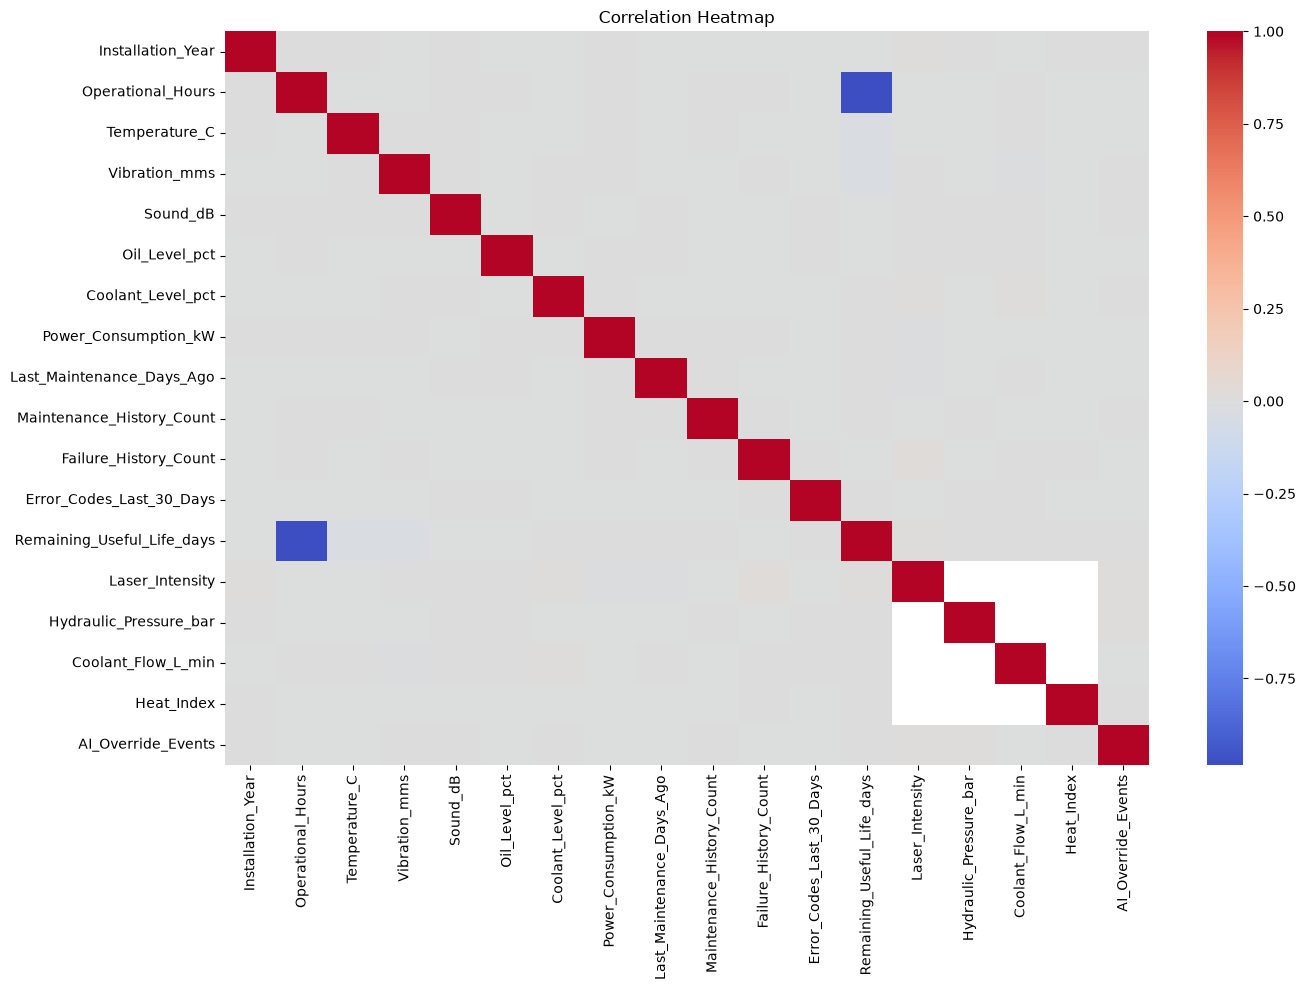

In [8]:
# Correlation heatmap for numeric features
num_features = df.select_dtypes(include=[np.number])
if "Failure_Within_7_Days" in num_features.columns:
    num_features = num_features.drop(columns=["Failure_Within_7_Days"])
plt.figure(figsize=(14, 10))
sns.heatmap(num_features.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

<a id = "8"></a><br>
<font color = "DeepSkyBlue">**Failure rate by machine type**

This section calculates and visualizes the average failure rate for each machine type by grouping the data and computing the mean of the Failure_Within_7_Days variable. The resulting bar chart highlights which machine types are most prone to failure within a 7-day window, aiding in risk assessment and maintenance prioritization.

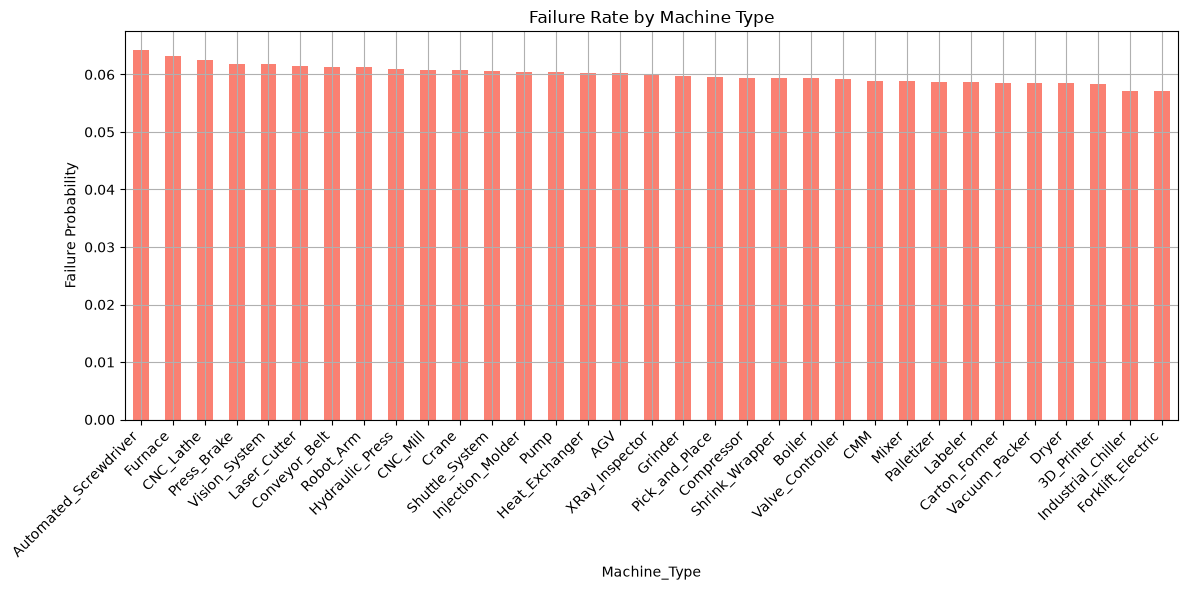

In [9]:
# Failure rate by machine type
failure_by_type = df.groupby("Machine_Type")["Failure_Within_7_Days"].mean().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
failure_by_type.plot(kind="bar", color="salmon")
plt.title("Failure Rate by Machine Type")
plt.ylabel("Failure Probability")
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.tight_layout()
plt.show()

<a id = "9"></a><br>
<font color = "DeepSkyBlue">**Predictive Model: Random Forest Classifier**

This section builds a binary classification model using a Random Forest to predict whether a machine will fail within the next 7 days. It includes data preprocessing with mean imputation, a train-test split, model training, and evaluation using accuracy, a confusion matrix, and a detailed classification report. The results help assess the model's ability to detect at-risk machines.

In [10]:
# --- Predictive Model: Random Forest Classifier ---
print("\n--- Random Forest Classification Model ---")
features = df.select_dtypes(include=[np.number]).drop(columns=["Remaining_Useful_Life_days", "Failure_Within_7_Days"], errors="ignore")
target = df["Failure_Within_7_Days"]
imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(features)
y = target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nAccuracy:", accuracy_score(y_test, y_pred))


--- Random Forest Classification Model ---

Confusion Matrix:
 [[92456  1584]
 [ 2072  3888]]

Classification Report:
               precision    recall  f1-score   support

       False       0.98      0.98      0.98     94040
        True       0.71      0.65      0.68      5960

    accuracy                           0.96    100000
   macro avg       0.84      0.82      0.83    100000
weighted avg       0.96      0.96      0.96    100000


Accuracy: 0.96344


<a id = "10"></a><br>
<font color = "DeepSkyBlue">**SHAP Explainability**

This section uses SHAP (SHapley Additive exPlanations) to interpret the Random Forest model's predictions. It calculates SHAP values for the first 100 training samples and visualizes feature importance, showing which input variables most influence the model’s decision to predict a machine failure.

(100, 17) (100, 17)


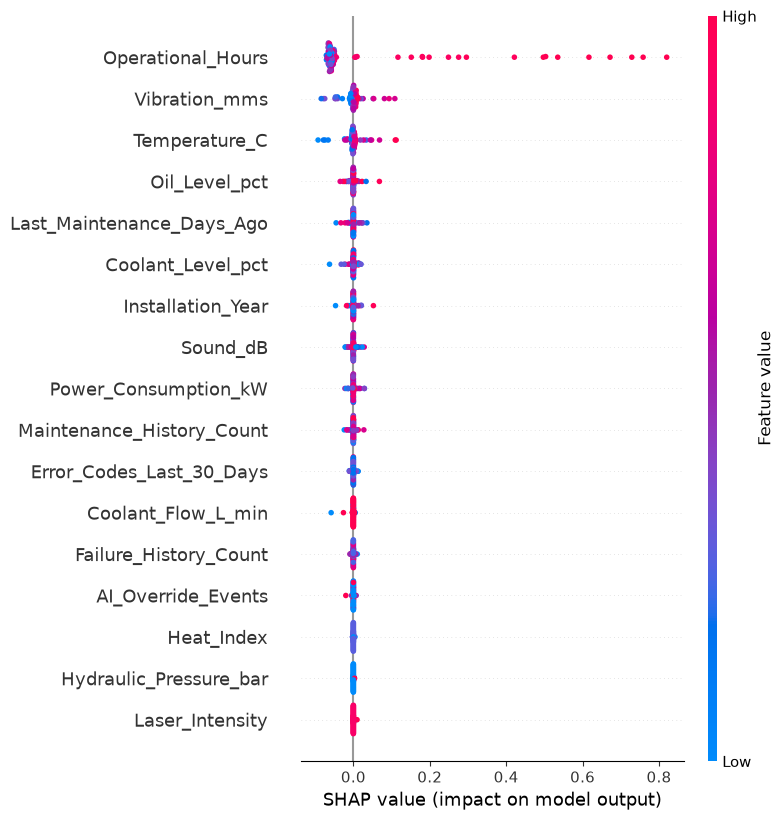

In [12]:
# --- SHAP Explainability ---
# --- SHAP Explainability ---
import numpy as np
import pandas as pd
import shap

X_sample = pd.DataFrame(X_train[:100], columns=features.columns)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)

# Pick the positive class (class 1) correctly, whatever format SHAP returns
if isinstance(shap_values, list):          # old SHAP: list per class
    sv = shap_values[1]
elif shap_values.ndim == 3:                 # new SHAP: (samples, features, classes)
    sv = shap_values[:, :, 1]
else:                                       # binary XGBoost/LightGBM: already 2D
    sv = shap_values

print(sv.shape, X_sample.shape)  # both should be (100, n_features)

shap.summary_plot(sv, X_sample)

<a id = "11"></a><br>
<font color = "DeepSkyBlue">**RUL Regression Model**

This section builds a regression model using a Random Forest Regressor to predict the Remaining_Useful_Life_days of machines. After preparing the data and splitting it into training and testing sets, the model is trained and evaluated using Mean Squared Error (MSE) and R² score to measure prediction accuracy for continuous outcomes.

In [13]:
# --- RUL Regression Model ---
print("\n--- RUL Regression Model ---")
reg_target = df["Remaining_Useful_Life_days"]
X_reg = imputer.fit_transform(features)
y_reg = reg_target
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
reg = RandomForestRegressor(n_estimators=100, random_state=42)
reg.fit(Xr_train, yr_train)
reg_pred = reg.predict(Xr_test)
print("\nMSE:", mean_squared_error(yr_test, reg_pred))
print("R2 Score:", r2_score(yr_test, reg_pred))


--- RUL Regression Model ---

MSE: 2415.091713251
R2 Score: 0.9710187183482478


<a id = "12"></a><br>
<font color = "DeepSkyBlue">**Feature Engineering: Binary Threshold Flags**

This section performs simple feature engineering by creating binary flags: High_Vibration for machines with vibration above 20 mm/s, and Low_Oil for those with oil levels below 30%. It then visualizes the relationship between high vibration and failure rates, offering intuitive insights for maintenance decision-making.

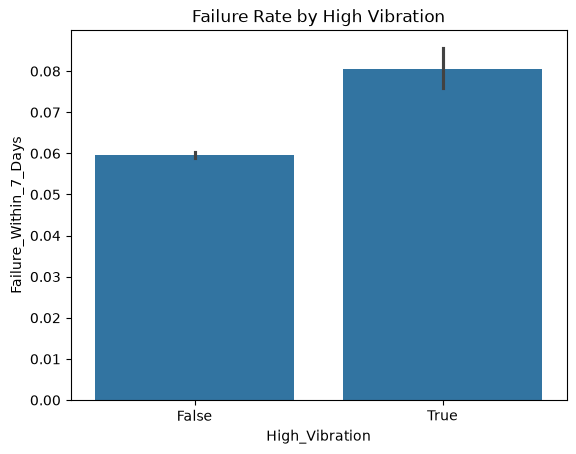

In [14]:
# --- Feature Engineering: Binary Threshold Flags ---
df["High_Vibration"] = df["Vibration_mms"] > 20
df["Low_Oil"] = df["Oil_Level_pct"] < 30
sns.barplot(x="High_Vibration", y="Failure_Within_7_Days", data=df)
plt.title("Failure Rate by High Vibration")
plt.show()

<a id = "13"></a><br>
<font color = "DeepSkyBlue">**Model Comparison: XGBoost vs LightGBM**

This section compares two advanced gradient boosting models—XGBoost and LightGBM—for predicting machine failure within 7 days. Both models are trained on the same dataset, and their accuracy scores are printed to evaluate performance relative to the earlier Random Forest model. This helps identify the most effective algorithm for the classification task.

In [13]:
# --- Model Comparison: XGBoost vs LightGBM ---
xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric="logloss")
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
print("\nXGBoost Accuracy:", accuracy_score(y_test, xgb_pred))

lgb_model = lgb.LGBMClassifier()
lgb_model.fit(X_train, y_train)
lgb_pred = lgb_model.predict(X_test)
print("LightGBM Accuracy:", accuracy_score(y_test, lgb_pred))


XGBoost Accuracy: 0.96284
[LightGBM] [Info] Number of positive: 24072, number of negative: 375928
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.030229 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3152
[LightGBM] [Info] Number of data points in the train set: 400000, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.060180 -> initscore=-2.748348
[LightGBM] [Info] Start training from score -2.748348
LightGBM Accuracy: 0.96405


<a id = "14"></a><br>
<font color = "DeepSkyBlue">**Failure Clustering (KMeans on PCA)**

This section applies dimensionality reduction using PCA to project the high-dimensional sensor data into two principal components. It then performs KMeans clustering to group machines into three distinct clusters based on their sensor profiles. The resulting scatter plot visualizes these clusters, helping uncover hidden patterns or operational groupings within the dataset.

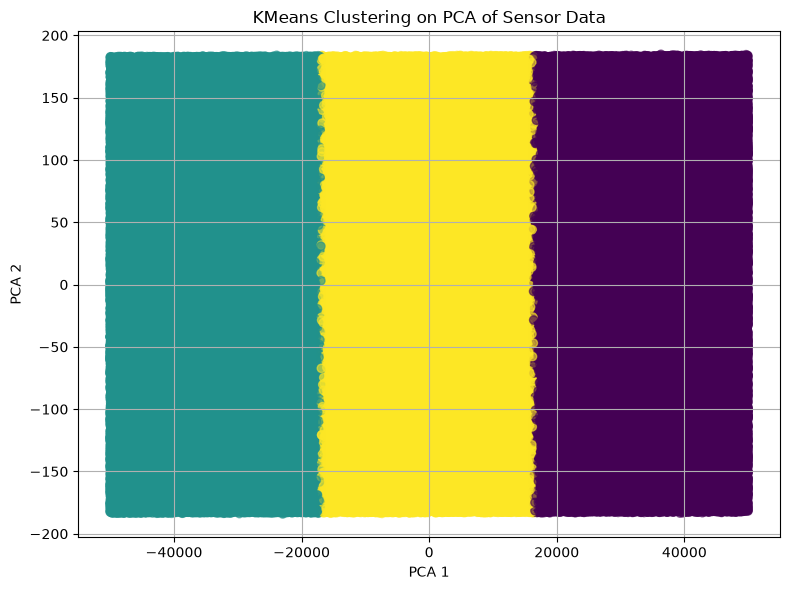

In [15]:
# --- Failure Clustering (KMeans on PCA) ---
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X)
kmeans = KMeans(n_clusters=3, random_state=42)
labels = kmeans.fit_predict(pca_result)
plt.figure(figsize=(8, 6))
plt.scatter(pca_result[:, 0], pca_result[:, 1], c=labels, cmap="viridis", alpha=0.6)
plt.title("KMeans Clustering on PCA of Sensor Data")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.grid(True)
plt.tight_layout()
plt.show()